# Variational algorithms: VQE and QAOA

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Broum/UKP_IQC_materials/blob/main/07_Qiskit_VQE_QAOA_vlq_qaas053.ipynb)

Content (textbook, chapter 9):
* VQE on one qubit
  * the energy from measurements in two bases
  * the energy landscape and the hybrid loop
  * a bad ansatz, shot noise and barren plateaus
* From a binary problem to an Ising Hamiltonian
* QAOA for MaxCut
  * one edge, layer by layer
  * a triangle and a ring
  * from the expectation value to a solution

**How to use this notebook.** As in 05 and 06: a cell after **Your turn** says what we want and leaves the rest to you, with a collapsed
solution below it. Nothing later depends on your cell. The figures are drawn by helper functions from the collapsed cell in section 0;
every figure is a single line such as `show_vqe_landscape()`.

## 0. Setup

In Colab uncomment and run the first cell after every runtime restart. Then run the two cells below it, the second one holds the plotting
helpers and is collapsed.

In [ ]:
# %pip install -q qiskit qiskit-aer pylatexenc matplotlib scipy

In [ ]:
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator

print(qiskit.__version__)

shots = 1000
sim = AerSimulator()


def run(qc: QuantumCircuit, shots: int = shots) -> dict:
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

2.1.2


In [ ]:
#@title Plotting helpers (run it, no need to read it)
from matplotlib.patches import Patch


def _clean(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)


def _pi_label(x: float) -> str:
    f = Fraction(x / np.pi).limit_denominator(16)
    if abs(float(f) * np.pi - x) > 1e-6:
        return f'{x:.3f}'
    if f == 0:
        return '0'
    num = '' if f.numerator == 1 else str(f.numerator)
    return rf'${num}\pi$' if f.denominator == 1 else rf'${num}\pi/{f.denominator}$'


def _pi_axis(ax, top: float, step: float, axis: str = 'x'):
    ticks = np.arange(0, top + 1e-9, step)
    (ax.set_xticks if axis == 'x' else ax.set_yticks)(ticks, [_pi_label(t) for t in ticks])


def _energy_curve(ax):
    t = np.linspace(0, 2 * np.pi, 400)
    ax.plot(t, np.cos(t) + np.sin(t), color='0.35', label=r'exact $E(\theta)=\sqrt{2}\cos(\theta-\pi/4)$')
    ax.axhline(-np.sqrt(2), color='tab:red', ls='--', lw=1, label=r'$E_0=-\sqrt{2}$')
    _pi_axis(ax, 2 * np.pi, np.pi / 4)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel('energy')
    _clean(ax)


def _bloch_xz(ax):
    t = np.linspace(0, 2 * np.pi, 400)
    ax.scatter(np.sin(t), np.cos(t), c=np.sin(t) + np.cos(t), cmap='coolwarm', s=10,
               vmin=-np.sqrt(2), vmax=np.sqrt(2))
    ax.annotate('', xy=(0.72, 0.72), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color='0.3', lw=1.5))
    ax.text(0.8, 0.86, '(1, 0, 1)', color='0.3', fontsize=9, ha='left')
    s = 1 / np.sqrt(2)
    ax.plot([0, -s], [0, -s], color='tab:red', lw=1, ls=':')
    ax.plot(-s, -s, marker='*', ms=18, color='tab:red', zorder=5)
    ax.text(-s - 0.15, -s - 0.12, 'ground state\n' + r'$\theta^*=5\pi/4$', color='tab:red', ha='right', va='top', fontsize=9)
    for (x, z, label) in [(0, 1.13, r'$|0\rangle$'), (0, -1.13, r'$|1\rangle$'),
                          (1.18, 0, r'$|+\rangle$'), (-1.18, 0, r'$|-\rangle$')]:
        ax.text(x, z, label, ha='center', va='center', fontsize=12)
    arc = np.linspace(0, np.pi / 3, 30)
    ax.plot(0.35 * np.sin(arc), 0.35 * np.cos(arc), color='0.3', lw=1)
    ax.annotate('', xy=(0.35 * np.sin(np.pi / 3), 0.35 * np.cos(np.pi / 3)),
                xytext=(0.35 * np.sin(np.pi / 3.3), 0.35 * np.cos(np.pi / 3.3)),
                arrowprops=dict(arrowstyle='-|>', color='0.3'))
    ax.text(0.2, 0.42, r'$\theta$', fontsize=11)
    ax.set_xlim(-1.75, 1.5)
    ax.set_ylim(-1.35, 1.35)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title('Bloch vector of $R_Y(\\theta)|0\\rangle$ (xz plane)\ncolour = energy $E = x + z$', fontsize=10)


def show_vqe_landscape(thetas=None, measured=None):
    fig, (ax, ax_b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.7, 1]})
    _energy_curve(ax)
    if measured is not None:
        ax.plot(thetas, measured, 'o', color='tab:blue', label='measured')
    ax.legend(fontsize=8, loc='upper right')
    _bloch_xz(ax_b)
    plt.tight_layout()
    plt.show()


def show_optimization(history):
    th = np.array([h[0] for h in history])
    E = np.array([h[1] for h in history])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
    ax1.plot(range(1, len(E) + 1), E, 'o-', ms=4)
    ax1.axhline(-np.sqrt(2), color='tab:red', ls='--', lw=1, label=r'$E_0=-\sqrt{2}$')
    ax1.set_xlabel('energy evaluation (2 circuits each)')
    ax1.set_ylabel('measured energy')
    ax1.legend()
    _clean(ax1)
    _energy_curve(ax2)
    sc = ax2.scatter(th % (2 * np.pi), E, c=range(len(E)), cmap='viridis', zorder=3, s=30)
    plt.colorbar(sc, ax=ax2, label='evaluation')
    ax2.set_title('where the optimiser asked')
    plt.tight_layout()
    plt.show()


def show_landscapes(curves: dict, thetas):
    fig, ax = plt.subplots(figsize=(9, 3.8))
    for (name, E), m in zip(curves.items(), 'osd^v'):
        ax.plot(thetas, E, marker=m, ms=5, label=name)
    ax.axhline(-np.sqrt(2), color='tab:red', ls='--', lw=1, label=r'$E_0=-\sqrt{2}$')
    _pi_axis(ax, 2 * np.pi, np.pi / 4)
    ax.set_xlabel(r'$\theta$')
    ax.set_ylabel(r'measured $\langle Z + X\rangle$')
    ax.legend(fontsize=8, loc='upper right', ncol=2)
    _clean(ax)
    plt.show()


def show_shot_noise(results: dict):
    jitter = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for k, (N, Es) in enumerate(results.items()):
        ax.plot(k + jitter.uniform(-0.1, 0.1, len(Es)), Es, 'o', color='tab:blue', alpha=0.6, ms=5)
        sigma = 1 / np.sqrt(N)
        ax.errorbar(k + 0.28, -np.sqrt(2), yerr=sigma, fmt='none', ecolor='tab:red', capsize=6, lw=2)
    ax.axhline(-np.sqrt(2), color='tab:red', ls='--', lw=1)
    ax.set_xticks(range(len(results)), [f'N = {N}\n' + rf'$\sigma$ (9.16) = {1 / np.sqrt(N):.3f}' + f'\nmeasured {np.std(Es, ddof=1):.3f}'
                                         for N, Es in results.items()])
    ax.set_xlim(-0.5, len(results) - 0.4)
    ax.set_ylabel(r'estimate $\hat E(\theta^*)$')
    ax.set_title(r'repeated estimates at $\theta^*=5\pi/4$; red bar = $\pm\sigma$')
    _clean(ax)
    plt.show()


def show_gradient_variance(ns, var_global, var_local):
    ns = np.array(list(ns))
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.semilogy(ns, var_global, 'o', color='tab:red', label='global cost, measured')
    ax.semilogy(ns, (3 / 8)**(ns - 1) / 8, '--', color='tab:red', lw=1, label=r'$(3/8)^{n-1}/8$, eq. (9.27)')
    ax.semilogy(ns, var_local, 's', color='tab:blue', label='local cost, measured')
    ax.semilogy(ns, 1 / (8 * ns**2), '--', color='tab:blue', lw=1, label=r'$1/(8n^2)$, eq. (9.29)')
    ax.set_xlabel('number of qubits $n$')
    ax.set_ylabel(r'Var$(\partial C/\partial\theta_1)$ over random $\theta$')
    ax.set_xticks(ns)
    ax.legend(fontsize=9)
    _clean(ax)
    plt.show()


def show_penalty(g, Ps):
    strings = ['00', '01', '10', '11']
    fig, axes = plt.subplots(1, len(Ps), figsize=(3.3 * len(Ps), 3.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, P in zip(axes, Ps):
        vals = np.array([g(int(s[0]), int(s[1])) + P * (int(s[0]) + int(s[1]) - 1)**2 for s in strings])
        feasible = np.array([s in ('01', '10') for s in strings])
        ax.bar(strings, vals, color=np.where(feasible, 'tab:green', 'tab:gray'))
        minima = np.isclose(vals, vals.min())
        for i in np.flatnonzero(minima):
            ax.text(i, vals[i], 'min', ha='center', va='top' if vals[i] < 0 else 'bottom', fontweight='bold')
        if feasible[minima].all():
            status = 'constraint holds'
        elif feasible[minima].any():
            status = 'tie'
        else:
            status = 'constraint broken'
        ax.set_title(f'P = {P}: {status}')
        ax.axhline(0, color='0.5', lw=0.8)
        ax.set_xlabel('$x_1x_2$')
        _clean(ax)
    axes[0].set_ylabel('$f_P(x_1, x_2)$')
    axes[0].legend(handles=[Patch(color='tab:green', label='$x_1+x_2=1$'), Patch(color='tab:gray', label='violates it')],
                    fontsize=8, loc='upper right')
    plt.tight_layout()
    plt.show()


def _wheels(ax, amps, labels, scale):
    # One wheel per amplitude: disc size = modulus, hand and colour = phase
    for c, a in enumerate(amps):
        a = a / scale * 0.42
        phase = np.angle(a) % (2 * np.pi)
        ax.add_patch(plt.Circle((c, 0), 0.42, fill=False, color='0.8', linewidth=1))
        if abs(a) > 1e-6:
            ax.add_patch(plt.Circle((c, 0), abs(a), color=plt.cm.twilight(phase / (2 * np.pi))))
            hand = 'white' if np.pi / 2 < phase < 3 * np.pi / 2 else 'black'
            ax.plot([c, c + a.real], [0, a.imag], color=hand, linewidth=1.5, solid_capstyle='round')
    ax.set_xlim(-0.55, len(amps) - 0.45)
    ax.set_ylim(-0.55, 0.55)
    ax.set_aspect('equal')
    ax.set_xticks(range(len(amps)), labels)
    ax.set_yticks([])
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)


def show_qaoa_stages(gamma: float, beta: float):
    qc = QuantumCircuit(2)
    qc.h([0, 1])
    stages = [('after $H$', Statevector(qc))]
    qc.rzz(-gamma, 0, 1)
    stages.append((r'after cost layer $e^{-i\gamma H_C}$', Statevector(qc)))
    qc.rx(2 * beta, [0, 1])
    stages.append((r'after mixer $e^{-i\beta H_M}$', Statevector(qc)))
    labels = ['00', '01', '10', '11']
    colors = ['tab:gray', 'tab:green', 'tab:green', 'tab:gray']
    fig, axes = plt.subplots(3, 2, figsize=(9, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
    for r, (name, sv) in enumerate(stages):
        amps = sv.data
        ref = amps[np.flatnonzero(np.abs(amps) > 1e-6)[0]]
        _wheels(axes[r, 0], amps * np.exp(-1j * np.angle(ref)), labels, scale=1 / np.sqrt(2))
        axes[r, 0].set_ylabel(name, rotation=0, ha='right', va='center', fontsize=10)
        probs = np.abs(amps)**2
        axes[r, 1].bar(labels, probs, color=colors)
        for i, p in enumerate(probs):
            axes[r, 1].text(i, p + 0.02, f'{p:.2f}', ha='center', fontsize=9)
        axes[r, 1].set_ylim(0, 1.1)
        _clean(axes[r, 1])
    axes[0, 0].set_title('amplitudes (size = modulus, hand = phase)', fontsize=10)
    axes[0, 1].set_title('probabilities (green = edge cut)', fontsize=10)
    fig.suptitle(f'one edge, $\\gamma$ = {_pi_label(gamma)}, $\\beta$ = {_pi_label(beta)}')
    plt.tight_layout()
    plt.show()


def show_heatmap(gammas, betas, F, marks=(), title=''):
    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(F, origin='lower', aspect='auto', cmap='viridis',
                   extent=[gammas[0], gammas[-1], betas[0], betas[-1]])
    plt.colorbar(im, ax=ax, label=r'expected cut $F_1(\gamma,\beta)$')
    b, g = np.unravel_index(F.argmax(), F.shape)
    ax.plot(gammas[g], betas[b], '*', color='white', ms=14, label=f'grid maximum {F.max():.3f}')
    for k, (gm, bm) in enumerate(marks):
        ax.plot(gm, bm, 'o', mfc='none', mec='tab:red', ms=16, mew=2, label='your points' if k == 0 else None)
    _pi_axis(ax, 2 * np.pi, np.pi / 2, 'x')
    _pi_axis(ax, np.pi / 2, np.pi / 8, 'y')
    ax.set_xlabel(r'$\gamma$ (cost)')
    ax.set_ylabel(r'$\beta$ (mixer)')
    ax.set_title(title)
    ax.legend(loc='upper right', fontsize=8, framealpha=0.8)
    plt.show()


def _draw_cut(ax, edges, bits):
    n = len(bits)
    x = bits[::-1]                       # x[i] is the bit of qubit i
    pos = [(np.sin(2 * np.pi * i / n), np.cos(2 * np.pi * i / n)) for i in range(n)]
    for i, j in edges:
        cut = x[i] != x[j]
        ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]], color='tab:red' if cut else '0.6',
                lw=3 if cut else 1.5, ls='-' if cut else '--', zorder=1)
    for i, (px, py) in enumerate(pos):
        ax.scatter(px, py, s=520, color='tab:orange' if x[i] == '1' else 'tab:blue', edgecolor='k', zorder=2)
        ax.text(px, py, str(i), color='white', ha='center', va='center', fontweight='bold', zorder=3)
    ax.set_xlim(-1.45, 1.45)
    ax.set_ylim(-1.45, 1.45)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f'{bits}: cut = {cut_value(bits, edges)}', fontsize=10)


def show_samples(edges, samples: dict):
    n = len(next(iter(next(iter(samples.values())))))
    cuts = {format(k, f'0{n}b'): cut_value(format(k, f'0{n}b'), edges) for k in range(2**n)}
    c_max = max(cuts.values())
    order = sorted(cuts, key=lambda s: (-cuts[s], s))
    fig, axes = plt.subplots(len(samples), 2, figsize=(12, 3 * len(samples)),
                             gridspec_kw={'width_ratios': [1, 4]}, squeeze=False)
    for row, (name, counts) in enumerate(samples.items()):
        total = sum(counts.values())
        probs = np.array([counts.get(s, 0) / total for s in order])
        mean = sum(counts[s] * cuts[s] for s in counts) / total
        p_opt = sum(counts[s] for s in counts if cuts[s] == c_max) / total
        top = max(counts, key=lambda s: (cuts[s], counts[s]))
        _draw_cut(axes[row, 0], edges, top)
        ax = axes[row, 1]
        ax.bar(range(len(order)), probs, color=[plt.cm.viridis(cuts[s] / c_max) for s in order])
        ax.axhline(1 / 2**n, color='0.3', ls=':', lw=1.2, label='random guess')
        for value in sorted(set(cuts.values()), reverse=True):
            idx = [i for i, s in enumerate(order) if cuts[s] == value]
            ax.axvline(idx[-1] + 0.5, color='0.85', lw=1)
            ax.text(np.mean(idx), 1.02, f'cut {value}', transform=ax.get_xaxis_transform(), ha='center', fontsize=9)
        ax.set_xticks(range(len(order)), order, rotation=90, fontsize=8 if n > 4 else 9)
        ax.set_xlim(-0.6, len(order) - 0.4)
        ax.set_ylabel('frequency')
        ax.set_title(f'{name}:  mean cut {mean:.2f} of {c_max},  P(optimum) = {p_opt:.2f}', pad=18)
        ax.legend(fontsize=8, loc='upper right')
        _clean(ax)
    plt.tight_layout()
    plt.show()


def show_success(qs, N_max=80):
    N = np.arange(1, N_max + 1)
    fig, ax = plt.subplots(figsize=(8, 3.8))
    for q in qs:
        ax.plot(N, 1 - (1 - q)**N, label=f'q = {q}')
    for target in (0.95, 0.99):
        ax.axhline(target, color='0.5', ls=':', lw=1)
        ax.text(N_max, target, f' {target:.0%}', va='center', fontsize=9)
    ax.set_xlabel('number of final samples $N$')
    ax.set_ylabel('P(at least one optimum)')
    ax.legend(loc='lower right')
    _clean(ax)
    plt.show()

## 1. VQE on one qubit

### 1.1 The variational loop

A short parametrised circuit, the **ansatz**, prepares $|\psi(\theta)\rangle = U(\theta)|0\rangle$. The quantum computer estimates the energy

$$E(\theta) = \langle\psi(\theta)|H|\psi(\theta)\rangle$$

from repeated measurements, and a classical optimiser proposes a better $\theta$:

$$\theta \;\longrightarrow\; \boxed{\text{QPU: prepare and measure, many shots}} \;\xrightarrow{\text{counts}}\;
\boxed{\text{CPU: estimate } E(\theta),\ \text{propose new } \theta} \;\longrightarrow\; \theta' \;\longrightarrow \cdots$$

**Why it works: the variational principle.** Write the state in the eigenbasis of $H$, $|\psi\rangle = \sum_k a_k|E_k\rangle$. Then

$$\langle\psi|H|\psi\rangle = \sum_k |a_k|^2 E_k \;\geq\; E_0 .$$

The energy is a weighted average of the eigenvalues, so it can never go below the lowest one. Every $\theta$ gives an upper bound on $E_0$,
and VQE (*variational quantum eigensolver*) pushes this bound down.

The textbook example (9.3) is

$$H = Z + X = \begin{pmatrix} 1 & 1\\ 1 & -1\end{pmatrix}, \qquad E_0 = -\sqrt2 .$$

We do not need a quantum computer for a $2\times 2$ matrix, it is here to see every step of VQE. In Qiskit a Hamiltonian is written as a
sum of Pauli strings, `SparsePauliOp`:

In [ ]:
H = SparsePauliOp(['Z', 'X'], [1, 1])
print(H.to_matrix().real)
print('eigenvalues:', np.linalg.eigvalsh(H.to_matrix()))
E0 = -np.sqrt(2)

[[ 1.  1.]
 [ 1. -1.]]
eigenvalues: [-1.41421356  1.41421356]


### 1.2 The ansatz $R_Y(\theta)|0\rangle$

$$|\psi(\theta)\rangle = R_Y(\theta)|0\rangle = \cos\tfrac\theta2|0\rangle + \sin\tfrac\theta2|1\rangle$$

**The energy splits into two terms.** The expectation value is linear, so a sum in $H$ gives a sum of expectation values:

$$E(\theta) = \langle\psi|(Z + X)|\psi\rangle = \langle\psi|Z|\psi\rangle + \langle\psi|X|\psi\rangle = \langle Z\rangle + \langle X\rangle .$$

This is the key step of the whole example: we never need $H$ as one object, only its Pauli terms one by one. For our ansatz both follow
in one line each (write $c = \cos\frac\theta2$, $s = \sin\frac\theta2$):

* $Z$ flips the sign of the $|1\rangle$ amplitude: $Z|\psi\rangle = c|0\rangle - s|1\rangle$, so $\langle Z\rangle = c^2 - s^2 = \cos\theta$.
* $X$ swaps the two amplitudes: $X|\psi\rangle = s|0\rangle + c|1\rangle$, so $\langle X\rangle = sc + cs = \sin\theta$.

Together

$$E(\theta) = \cos\theta + \sin\theta = \sqrt2\cos(\theta - \pi/4), \qquad \theta^* = 5\pi/4,\quad E(\theta^*) = -\sqrt2 .$$

On the Bloch sphere $\langle X\rangle$ and $\langle Z\rangle$ are the $x$ and $z$ components of the Bloch vector $(\sin\theta,\ 0,\ \cos\theta)$, so
$E = x + z$ is its projection onto the direction $(1, 0, 1)$. $R_Y$ moves the vector around the circle in the xz plane, and the ground
state is the point of the circle opposite to $(1, 0, 1)$.

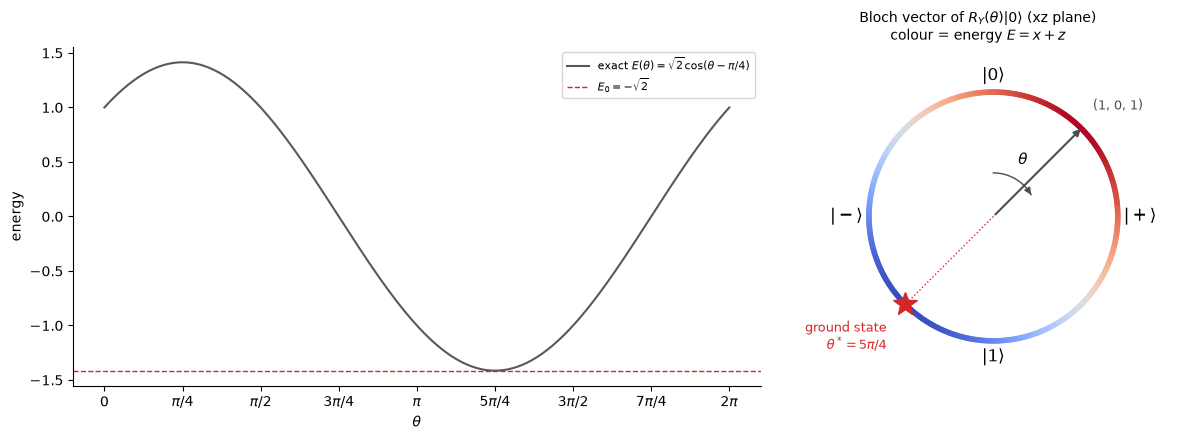

In [ ]:
show_vqe_landscape()

### 1.3 The energy from measurements

On a quantum computer we cannot evaluate the formulas of 1.2: we prepare $|\psi(\theta)\rangle$, measure, and get counts of 0s and 1s.
Three steps take us from counts to $E$.

**Why two circuits.** A measurement gives one outcome in one basis, the computational basis, which is the eigenbasis of $Z$. To measure
$H$ in one go we would need the eigenbasis of $H$, and that is exactly what we are looking for. $Z$ and $X$ do not commute, so no single
basis gives both of them either. So we use 1.2: estimate $\langle Z\rangle$ and $\langle X\rangle$ in **two separate circuits**, each with
its own shots, and add the two numbers. Every shot prepares the state anew, because the measurement destroys it.

**$\langle Z\rangle$ from counts.** $Z$ has eigenvalue $+1$ on $|0\rangle$ and $-1$ on $|1\rangle$, so $\langle Z\rangle$ is the average of the
outcomes counted as $\pm 1$:

$$\langle Z\rangle = (+1)\,p_0 + (-1)\,p_1 \approx \frac{N_0 - N_1}{N} .$$

For example 150 zeros and 850 ones out of $N = 1000$ give $\langle Z\rangle \approx -0.70$.

**$\langle X\rangle$ by a basis change.** The Hadamard gate, written $\mathsf H$ here so that it is not mixed up with the Hamiltonian $H$,
turns $Z$ into $X$: $X = \mathsf H Z \mathsf H$. Therefore

$$\langle X\rangle_\psi = \langle\psi|\mathsf H\, Z\, \mathsf H|\psi\rangle = \langle Z\rangle_{\psi'}, \qquad |\psi'\rangle = \mathsf H|\psi\rangle .$$

$\langle X\rangle$ of our state is $\langle Z\rangle$ of the rotated state. So we apply $\mathsf H$ just before the measurement, and the same
formula $(N_0 - N_1)/N$ now gives $\langle X\rangle$. In words: $\mathsf H$ maps $|+\rangle \to |0\rangle$ and $|-\rangle \to |1\rangle$
(the basis change from chapter 3), so outcome 0 now means "$+1$ of $X$".

The two circuits (textbook figure 9.3):

```
|0> ── RY(θ) ─────── measure  ->  N0, N1  ->  <Z>
|0> ── RY(θ) ── H ── measure  ->  N0, N1  ->  <X>
```

and the estimate of the energy is their sum:

$$\hat E(\theta) = \underbrace{\frac{N_0^{(Z)} - N_1^{(Z)}}{N_Z}}_{\approx\,\langle Z\rangle} + \underbrace{\frac{N_0^{(X)} - N_1^{(X)}}{N_X}}_{\approx\,\langle X\rangle} \qquad (9.15)$$

**Your turn.** For $\theta = 5\pi/4$:

1. Build `qc_z`: $R_Y(\theta)$, measure. Build `qc_x`: $R_Y(\theta)$, $\mathsf H$, measure. Run both with `run(...)`.
2. From the counts compute $\langle Z\rangle$, $\langle X\rangle$ and $\hat E$, and compare with $-\sqrt2 \approx -1.414$.
3. Run the cell several times. Does $\hat E$ sometimes come out *below* $-\sqrt2$? Does it break the variational principle?
4. Try $\theta = 0$ and $\theta = \pi/2$ and check against $E(\theta) = \cos\theta + \sin\theta$.

In [ ]:
theta = 5 * np.pi / 4

# qc_z = QuantumCircuit(1)
# qc_z.ry(theta, 0)
# qc_z.measure_all()
# qc_x = ...                  # the same, with qc_x.h(0) before the measurement
# counts_z, counts_x = run(qc_z), run(qc_x)
# z = (counts_z.get('0', 0) - counts_z.get('1', 0)) / shots
# ...

<details>
<summary>Solution</summary>

```python
theta = 5 * np.pi / 4

qc_z = QuantumCircuit(1)
qc_z.ry(theta, 0)
qc_z.measure_all()

qc_x = QuantumCircuit(1)
qc_x.ry(theta, 0)
qc_x.h(0)                     # X basis -> Z basis
qc_x.measure_all()

counts_z, counts_x = run(qc_z), run(qc_x)
z = (counts_z.get('0', 0) - counts_z.get('1', 0)) / shots
x = (counts_x.get('0', 0) - counts_x.get('1', 0)) / shots
print(counts_z, counts_x)
print(f'<Z> = {z:.3f}, <X> = {x:.3f}, E = {z + x:.3f}   (exact {E0:.3f})')

# 3. Yes, roughly every other run. That is fine: the true expectation <psi|H|psi> is never below E0,
#    but our number is a statistical estimate of it from 2 x 1000 shots (see 1.7).
qc_x.draw('mpl')
```

</details>

The same for any Hamiltonian $H = \sum_k c_k P_k$ written as Pauli strings: one circuit per string, rotate every qubit with $X$ by $\mathsf H$ and
every qubit with $Y$ by $S^\dagger$ followed by $\mathsf H$, measure, and average the product of the $\pm 1$ outcomes of the qubits that take part. We use these
two functions from now on.

In [ ]:
def measure_pauli(prepare: QuantumCircuit, label: str, shots: int = shots) -> float:
    # Estimate <P> for a Pauli string such as 'ZX' (Qiskit order: the last letter acts on qubit 0)
    if set(label) == {'I'}:
        return 1.0
    qc = prepare.copy()
    for q, p in enumerate(reversed(label)):
        if p == 'X':
            qc.h(q)
        elif p == 'Y':
            qc.sdg(q)
            qc.h(q)
    qc.measure_all()
    total = 0
    for bits, n in run(qc, shots).items():
        ones = sum(bits[::-1][q] == '1' for q, p in enumerate(reversed(label)) if p != 'I')
        total += (-1)**ones * n
    return total / shots


def energy(prepare: QuantumCircuit, H: SparsePauliOp, shots: int = shots) -> float:
    # <H> = sum_k c_k <P_k>, one measurement setting per Pauli string
    return sum(c.real * measure_pauli(prepare, label, shots) for label, c in H.to_list())


def ry_ansatz(theta: float) -> QuantumCircuit:
    qc = QuantumCircuit(1)
    qc.ry(theta, 0)
    return qc


print('E(5pi/4) =', energy(ry_ansatz(5 * np.pi / 4), H))

/home/broum/miniconda3/envs/vlq_qaas053/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


E(5pi/4) = -1.446


### 1.4 The landscape from measurements

25 values of $\theta$, two circuits of 1000 shots each:

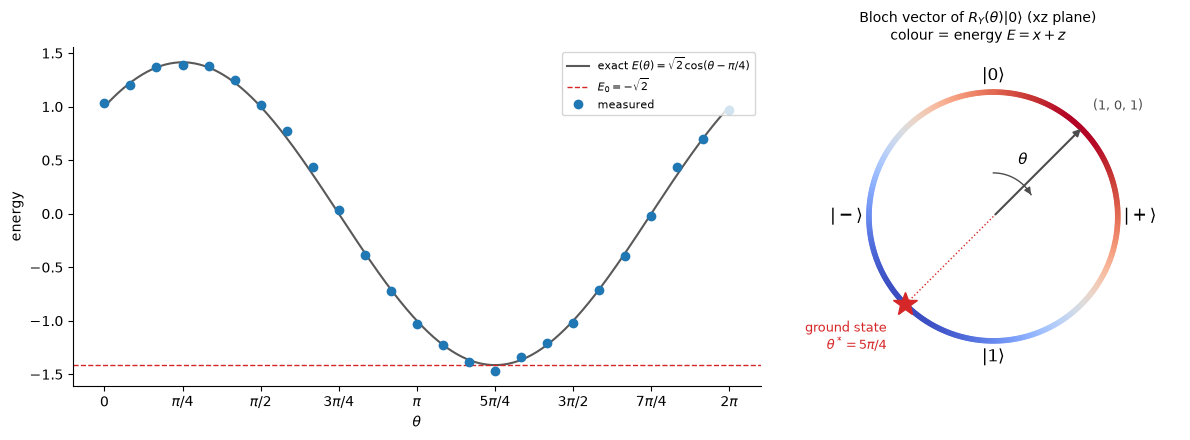

In [ ]:
thetas = np.linspace(0, 2 * np.pi, 25)
measured = [energy(ry_ansatz(theta), H) for theta in thetas]
show_vqe_landscape(thetas, measured)

### 1.5 The hybrid loop

In a real problem we cannot draw the whole landscape: with many parameters a grid is far too big. The optimiser only asks for $\hat E$ at the
points it chooses. We use COBYLA from SciPy, which needs no gradient. Every call of `cost` is one energy evaluation, that is 2 circuits
with 1000 shots each.

theta = 4.100   (5pi/4 = 3.927), 17 energy evaluations
optimiser value     E = -1.4380


re-measured, 10^5 shots: E = -1.3937   (E0 = -1.4142)


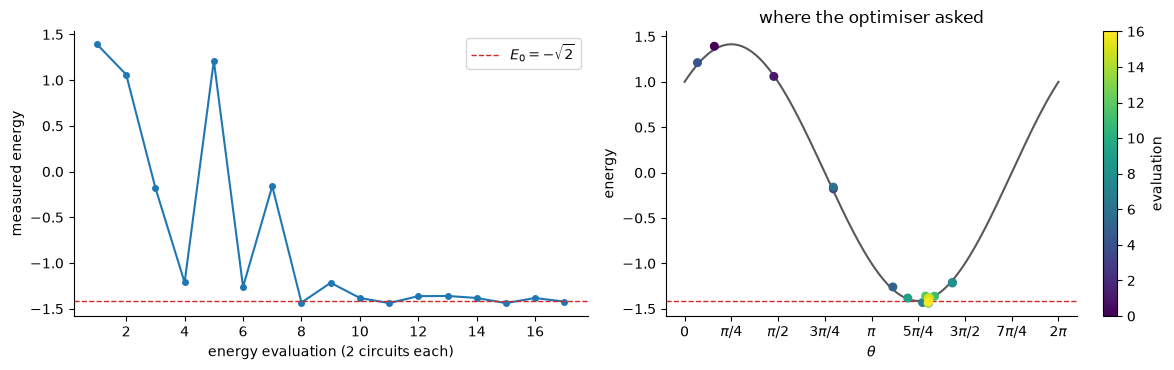

In [ ]:
history = []


def cost(params):
    E = energy(ry_ansatz(params[0]), H)
    history.append((params[0], E))
    return E


result = minimize(cost, x0=[0.5], method='COBYLA', options={'maxiter': 30})
theta_best = result.x[0]
print(f'theta = {theta_best % (2 * np.pi):.3f}   (5pi/4 = {5 * np.pi / 4:.3f}), {len(history)} energy evaluations')
print(f'optimiser value     E = {result.fun:.4f}')
print(f're-measured, 10^5 shots: E = {energy(ry_ansatz(theta_best), H, shots=100_000):.4f}   (E0 = {E0:.4f})')
show_optimization(history)

The last line measures the final $\theta$ once more, independently. The value the optimiser reports was picked *because* it was low, so it is
biased downwards by the noise; a fresh measurement removes that bias (textbook 9.7.3).

**Your turn.**

1. How many state preparations (shots) did the whole optimisation cost? With $K$ evaluations, $G$ settings and $N$ shots it is $KGN$.
2. Change the cost function to use only `shots=20` and run the loop again. What happens to the path and to the final $\theta$?

In [ ]:
# print(...)

<details>
<summary>Solution</summary>

```python
print('state preparations:', len(history) * 2 * shots)     # about 30 x 2 x 1000 = 60 000 for one parameter

# 2. In cost: E = energy(ry_ansatz(params[0]), H, shots=20)
#    The measured points scatter by about 1/sqrt(20) ~ 0.2 around the curve, the optimiser follows the noise,
#    and the final theta is typically off by a few tenths. More shots = smoother landscape = better parameters, but more QPU time.
```

</details>

### 1.6 A bad ansatz

VQE can only find states that the ansatz can prepare. With $E_A = \min_\theta E(\theta)$ the best value within the ansatz,

$$E_0 \;\le\; E_A \;\le\; E(\hat\theta) \qquad (9.7)$$

The first gap is the *ansatz error*, the second the *optimisation error*.

**Your turn.**

1. Write `rx_ansatz` and `rz_ansatz` (copy `ry_ansatz` and change one letter).
2. Measure the energy of $H = Z + X$ on the grid `thetas` for both and compare all three with
   `show_landscapes({'RY': measured, 'RX': E_rx, 'RZ': E_rz}, thetas)`.
3. Which circle on the Bloch sphere does each ansatz draw? Why can $R_X$ not go below $-1$? Why is $R_Z$ flat?
4. Textbook exercise 2: now take $H = Y$ (lowest eigenvalue $-1$). Which of the three ansätze can reach it?
   Try `energy(rx_ansatz(np.pi / 2), SparsePauliOp('Y'))`.

In [ ]:
# def rx_ansatz(theta):
#     ...
# def rz_ansatz(theta):
#     ...
# E_rx = [energy(rx_ansatz(theta), H) for theta in thetas]
# E_rz = ...
# show_landscapes({'RY': measured, 'RX': E_rx, 'RZ': E_rz}, thetas)

<details>
<summary>Solution</summary>

```python
def rx_ansatz(theta: float) -> QuantumCircuit:
    qc = QuantumCircuit(1)
    qc.rx(theta, 0)
    return qc


def rz_ansatz(theta: float) -> QuantumCircuit:
    qc = QuantumCircuit(1)
    qc.rz(theta, 0)
    return qc


E_rx = [energy(rx_ansatz(theta), H) for theta in thetas]
E_rz = [energy(rz_ansatz(theta), H) for theta in thetas]
show_landscapes({'RY': measured, 'RX': E_rx, 'RZ': E_rz}, thetas)

# 3. RY: circle in the xz plane, contains the ground state.
#    RX: circle in the yz plane, Bloch vector (0, -sin, cos), so <X> = 0 and E = cos(theta) >= -1.  Ansatz error sqrt2 - 1.
#    RZ: RZ|0> = e^{-i theta/2}|0>, only a global phase. One single state, E = 1, dE/dtheta = 0: nothing to optimise.
# 4. For H = Y: RY gives <Y> = 0 always, RX gives <Y> = -sin(theta), so RX(pi/2)|0> is the ground state.
print('H = Y, RX(pi/2):', energy(rx_ansatz(np.pi / 2), SparsePauliOp('Y')))
print('H = Y, RY(pi/2):', energy(ry_ansatz(np.pi / 2), SparsePauliOp('Y')))
```

</details>

### 1.7 Shot noise

The average of $N$ independent outcomes $\pm 1$ with mean $\mu$ has variance $(1 - \mu^2)/N$. With two independent settings

$$\mathrm{Var}(\hat E) = \frac{1 - \langle Z\rangle^2}{N_Z} + \frac{1 - \langle X\rangle^2}{N_X} \qquad (9.16)$$

**Your turn (on paper).** At $\theta^*$ we have $\langle Z\rangle = \langle X\rangle = -1/\sqrt2$. Compute the standard deviation $\sigma$ of $\hat E$
for $N_Z = N_X = 100,\ 1000,\ 10\,000$. Then run the cell below (textbook exercise 7, 20 repetitions each) and compare.

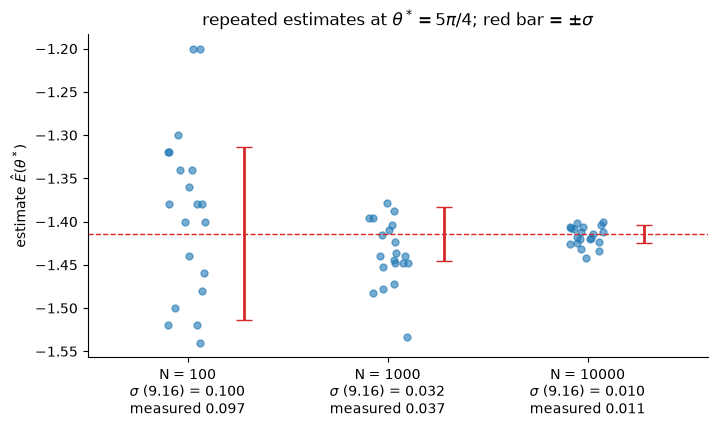

In [ ]:
results = {N: [energy(ry_ansatz(5 * np.pi / 4), H, shots=N) for _ in range(20)] for N in [100, 1000, 10_000]}
show_shot_noise(results)

<details>
<summary>Solution</summary>

$\mathrm{Var} = \frac{1/2}{N} + \frac{1/2}{N} = \frac1N$, so $\sigma = 1/\sqrt N = 0.1,\ 0.032,\ 0.01$.
Ten times smaller error costs a hundred times more shots.

</details>

### 1.8 Barren plateaus: when the landscape is flat

$R_Z$ in 1.6 had one *ineffective parameter*: it did not change the state at all. A **barren plateau** is something else: for a whole family of
circuits the *typical* gradient shrinks exponentially with the number of qubits $n$, so almost everywhere the landscape looks flat, even far
from the minimum.

The textbook toy example has no entanglement at all. Take $n$ qubits, each with its own $R_Y(\theta_i)|0\rangle$, and two cost functions
with the **same minimum** (all qubits in $|0\rangle$):

$$C_\text{global} = 1 - |\langle 0\cdots0|\psi\rangle|^2 = 1 - \prod_i \cos^2\tfrac{\theta_i}{2},
\qquad
C_\text{local} = \frac1n\sum_i \frac{1 - \langle Z_i\rangle}{2} = \frac1n\sum_i P(q_i = 1).$$

The global one asks "are *all* qubits right?", the local one checks each qubit separately.

The gradient is computed by the **parameter-shift rule** (9.60). For a gate $e^{-i\theta P/2}$ it is exact, not a finite difference, and costs
two extra circuits:

$$\frac{\partial C}{\partial\theta_j} = \frac12\Big[C(\theta_j + \tfrac\pi2) - C(\theta_j - \tfrac\pi2)\Big].$$

Below: 300 random parameter vectors for each $n$, the variance of $\partial C/\partial\theta_1$. We use the exact `Statevector` so that only
the effect itself is visible, without shot noise.

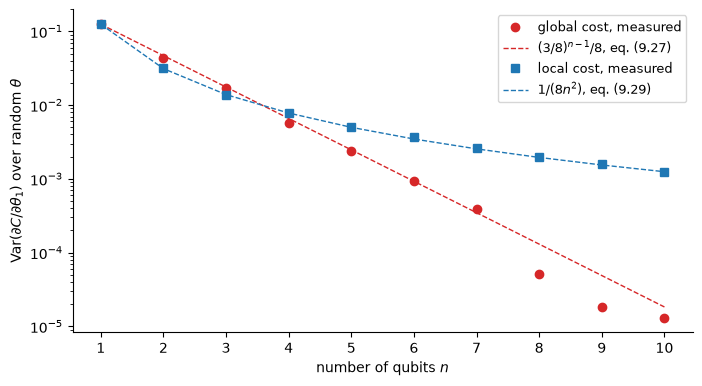

In [ ]:
def product_state(thetas) -> Statevector:
    qc = QuantumCircuit(len(thetas))
    for q, theta in enumerate(thetas):
        qc.ry(theta, q)
    return Statevector(qc)


def cost_global(thetas):
    return 1 - product_state(thetas).probabilities()[0]          # 1 - P(00...0)


def cost_local(thetas):
    psi = product_state(thetas)
    return np.mean([psi.probabilities([q])[1] for q in range(len(thetas))])


def shift_gradient(cost, thetas, j=0):
    plus, minus = thetas.copy(), thetas.copy()
    plus[j] += np.pi / 2
    minus[j] -= np.pi / 2
    return (cost(plus) - cost(minus)) / 2


rng = np.random.default_rng(7)
ns = range(1, 11)
var_global, var_local = [], []
for n in ns:
    samples = [rng.uniform(0, 2 * np.pi, n) for _ in range(300)]
    var_global.append(np.var([shift_gradient(cost_global, t) for t in samples]))
    var_local.append(np.var([shift_gradient(cost_local, t) for t in samples]))

show_gradient_variance(ns, var_global, var_local)

The global cost loses a factor $8/3$ per qubit, the local one only falls like $1/n^2$. Same minimum, same circuit, only the cost function
differs.

**Why more shots do not help.** To see a gradient of size $g$ above the shot noise we need $N \sim 1/g^2$ shots. For $g \sim 2^{-n}$ that is
$N \sim 4^n$: at $n = 50$ about $10^{30}$ shots. A gradient-free optimiser does not escape either: it compares values whose differences are
just as small.

**Possible cures** (textbook 9.3.4): use the structure of the problem in the ansatz, start shallow and add layers, initialise sensibly, prefer
local cost terms where the goal allows it, and keep the circuit short against noise.

## 2. From a binary problem to an Ising Hamiltonian

### 2.1 QUBO $\to$ Ising

Many optimisation problems are a **QUBO** (*quadratic unconstrained binary optimisation*):

$$\min_{x \in \{0,1\}^n} f(x), \qquad f(x) = c + \sum_i a_i x_i + \sum_{i<j} b_{ij} x_i x_j .$$

Substitute $x_i = (1 - z_i)/2$ with $z_i = \pm 1$, and replace $z_i$ by the operator $Z_i$:

$$H_C = c'\,I + \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j .$$

Since $Z_i|x\rangle = (-1)^{x_i}|x\rangle$, we get $H_C|x\rangle = f(x)|x\rangle$: $H_C$ is **diagonal** and its eigenvalues are the values of $f$.
The best bit string is the ground state of $H_C$. It is the same task as in VQE, only the Hamiltonian is diagonal.

**Qubit order in Qiskit.** The last letter of a Pauli label acts on qubit 0: `'IZ'` is $Z$ on qubit 0. We put $x_1$ on qubit 0 and $x_2$ on
qubit 1, so the basis state $|x_2 x_1\rangle$ has index $2x_2 + x_1$.

**Your turn.** Textbook example 9.4.2: $f(x_1, x_2) = 2x_1 - x_2 + 3x_1x_2$.

1. On paper: substitute $x_i = (1 - z_i)/2$ and collect the constant and the coefficients of $z_1$, $z_2$, $z_1z_2$.
2. Write $H_C$ as a `SparsePauliOp` and check that its diagonal is $f$ (textbook table 9.1). Which bit string is the minimum?
3. Textbook exercise 3: the same for $f = x_1 + 2x_2 - 4x_1x_2$.

In [ ]:
def f(x1, x2):
    return 2 * x1 - x2 + 3 * x1 * x2


# H_C = SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ'], [c, h1, h2, J])     # 'IZ' = Z_1 on qubit 0
# diagonal = H_C.to_matrix().diagonal().real
# for x1 in [0, 1]:
#     for x2 in [0, 1]:
#         print(x1, x2, f(x1, x2), diagonal[2 * x2 + x1])

<details>
<summary>Solution</summary>

```python
def f(x1, x2):
    return 2 * x1 - x2 + 3 * x1 * x2


# f = (1 - z1) - (1 - z2)/2 + 3/4 (1 - z1 - z2 + z1 z2) = 5/4 - 7/4 z1 - 1/4 z2 + 3/4 z1 z2
H_C = SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ'], [5 / 4, -7 / 4, -1 / 4, 3 / 4])
diagonal = H_C.to_matrix().diagonal().real
print('x1 x2   f   <x|H_C|x>')
for x1 in [0, 1]:
    for x2 in [0, 1]:
        print(f' {x1}  {x2}  {f(x1, x2):3}  {diagonal[2 * x2 + x1]:6.2f}')
# minimum: x1 x2 = 01, f = -1

# 3. f = x1 + 2 x2 - 4 x1 x2 = 1/2 + 1/2 z1 + 0 z2 - z1 z2,  minimum x1 x2 = 11 with f = -1
H_C3 = SparsePauliOp(['II', 'IZ', 'ZI', 'ZZ'], [1 / 2, 1 / 2, 0, -1])
print(H_C3.to_matrix().diagonal().real)      # order 00, 10, 01, 11 for (x1, x2): f = 0, 1, 2, -1
```

</details>

The constant $c'I$ does not change which bit string is best, and in $e^{-i\gamma H_C}$ it only gives a global phase, so circuits can drop it.
When we report the value of $f$, we must add it back.

### 2.2 Constraints as penalties

"Unconstrained" means the constraints have to go into $f$. For $x_1 + x_2 = 1$ we add $P(x_1 + x_2 - 1)^2 = P(1 - x_1 - x_2 + 2x_1x_2)$
(using $x_i^2 = x_i$), which is again quadratic. Textbook example: $g = -x_1 - x_2$. Without the constraint the best choice is $11$.

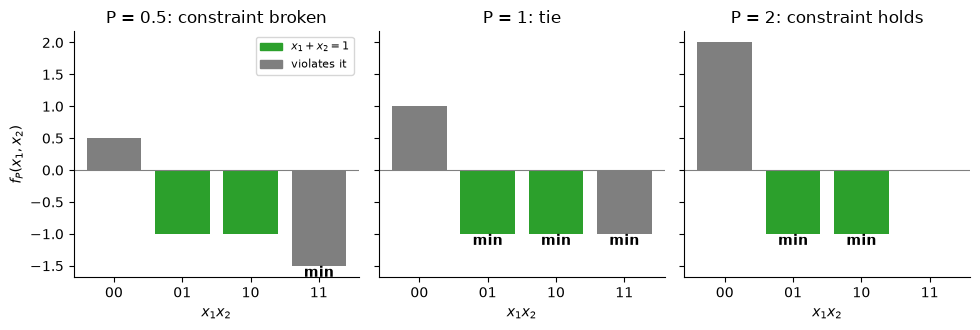

In [ ]:
show_penalty(lambda x1, x2: -x1 - x2, Ps=[0.5, 1, 2])

A small $P$ still lets the forbidden $11$ win, at $P = 1$ there is a tie, and only $P > 1$ forces the constraint. Too large a $P$ is not
free either: it stretches the range of the coefficients and the fine differences of $g$ get lost in the noise.

**Your turn.** Textbook exercise 4: $g = -2x_1 - x_2$. Find the smallest $P$ that enforces $x_1 + x_2 = 1$, first by trying values in
`show_penalty`, then on paper.

In [ ]:
# show_penalty(lambda x1, x2: ..., Ps=[...])

<details>
<summary>Solution</summary>

```python
show_penalty(lambda x1, x2: -2 * x1 - x2, Ps=[0.5, 1, 1.5])
# f_P(00) = P, f_P(01) = -1, f_P(10) = -2, f_P(11) = P - 3.
# The feasible minimum is 10 with -2; we need P - 3 > -2, i.e. P > 1. At P = 1 the forbidden 11 ties with 10.
```

</details>

## 3. QAOA for MaxCut

### 3.1 Cost layer and mixer layer

QAOA (*quantum approximate optimisation algorithm*) is a VQE with a special ansatz built from the problem itself. Start in
$|s\rangle = |+\rangle^{\otimes n}$ (all bit strings equally likely) and alternate two evolutions:

$$|\boldsymbol\gamma, \boldsymbol\beta\rangle = U_M(\beta_p)\,U_C(\gamma_p)\cdots U_M(\beta_1)\,U_C(\gamma_1)\,|s\rangle,
\qquad U_C(\gamma) = e^{-i\gamma H_C},\quad U_M(\beta) = e^{-i\beta H_M},\quad H_M = \sum_i X_i .$$

$p$ layers, $2p$ parameters. The optimiser tunes them to maximise (or minimise) $F_p = \langle\boldsymbol\gamma,\boldsymbol\beta|H_C|\boldsymbol\gamma,\boldsymbol\beta\rangle$.

**MaxCut.** Split the vertices of a graph into two groups (bit $x_i$ = group) so that as many edges as possible go between the groups.
An edge $(i, j)$ is cut when $x_i \neq x_j$. Since $Z_iZ_j = +1$ for equal and $-1$ for different bits,

$$H_C = \sum_{(i,j)\in E} \frac{I - Z_iZ_j}{2}, \qquad H_C|x\rangle = \text{cut}(x)\,|x\rangle .$$

**As gates.** Qiskit defines $R_{ZZ}(\vartheta) = e^{-i\vartheta Z\otimes Z/2}$, so one edge of the cost layer is
$e^{-i\gamma(I - Z_iZ_j)/2} = e^{-i\gamma/2}R_{ZZ}(-\gamma)$, i.e. `qc.rzz(-gamma, i, j)` up to a global phase. The $X_i$ commute, so the
mixer is $R_X(2\beta)$ on every qubit, `qc.rx(2 * beta, i)`.

**Why both layers?** The cost layer only multiplies each bit string by a phase, $a_x \to a_x e^{-i\gamma\,\text{cut}(x)}$; probabilities do
not change. The mixer mixes bit strings, so these phases can interfere and move probability towards good cuts.

### 3.2 One edge, layer by layer

**Your turn.** Two vertices, one edge, $p = 1$, with $\gamma = \pi/2$, $\beta = \pi/8$ (textbook 9.6).

1. Build the circuit: Hadamard on both qubits, the cost layer `rzz`, the mixer `rx` on both qubits.
2. Print `Statevector(qc).probabilities().round(3)` (order $00, 01, 10, 11$). The textbook says only $01$ and $10$ remain, each with probability $1/2$.
3. Delete the mixer line and print the probabilities again. What do you see?

In [ ]:
gamma, beta = np.pi / 2, np.pi / 8

# qc = QuantumCircuit(2)
# qc.h(...)
# qc.rzz(...)              # cost layer
# qc.rx(...)               # mixer
# print(Statevector(qc).probabilities().round(3))      # order 00, 01, 10, 11

<details>
<summary>Solution</summary>

```python
gamma, beta = np.pi / 2, np.pi / 8

qc = QuantumCircuit(2)
qc.h([0, 1])
qc.rzz(-gamma, 0, 1)       # cost layer
qc.rx(2 * beta, [0, 1])    # mixer
print(Statevector(qc).probabilities().round(3))      # order 00, 01, 10, 11: [0, 0.5, 0.5, 0]

# 3. Without the mixer all four probabilities stay 1/4: the cost layer changes phases only.
qc.draw('mpl')
```

</details>

The same as textbook table 9.2 in pictures. Look at the wheels: the cost layer turns the hands of $01$ and $10$ by $-\gamma$ and leaves the sizes
alone. The mixer lets the four amplitudes interfere, and at these angles they cancel exactly on $00$ and $11$. Try $\gamma = \pi/4$ or
$\beta = \pi/16$.

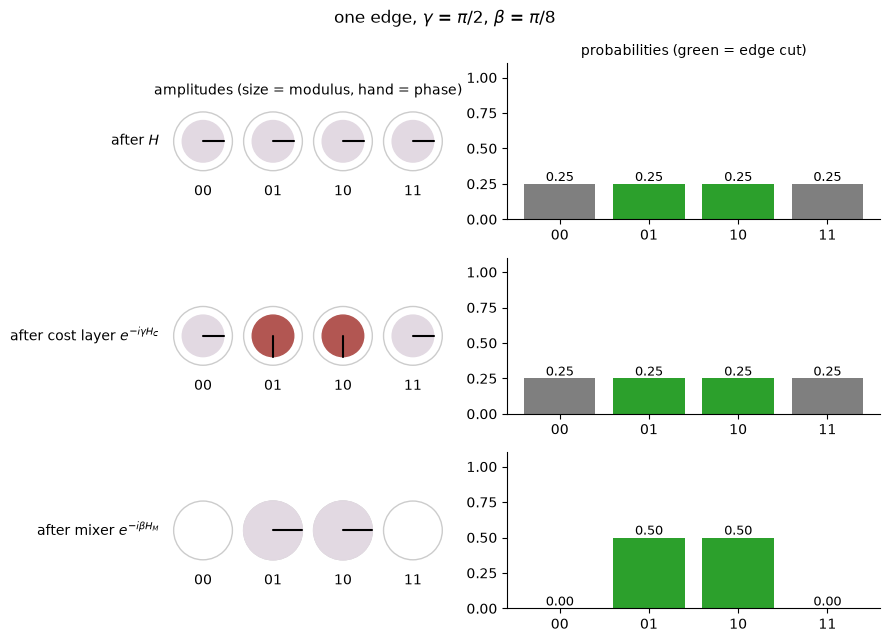

In [ ]:
show_qaoa_stages(gamma=np.pi / 2, beta=np.pi / 8)

From now on a general QAOA circuit for any graph, the cut value of a bit string, and the expected cut $F_p$. (Remember: the bit of qubit $i$
is `bits[::-1][i]`.)

F_1 = 0.9999999999999998


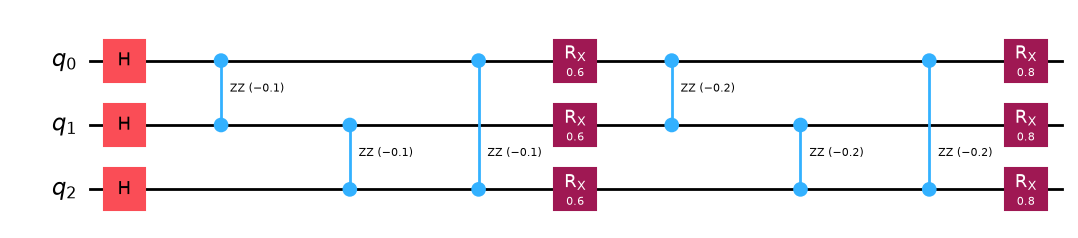

In [ ]:
def qaoa(edges, n: int, gammas, betas) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for gamma, beta in zip(gammas, betas):
        for i, j in edges:
            qc.rzz(-gamma, i, j)           # cost layer
        qc.rx(2 * beta, range(n))          # mixer
    return qc


def cut_value(bits: str, edges) -> int:
    x = bits[::-1]
    return sum(x[i] != x[j] for i, j in edges)


def expected_cut(qc: QuantumCircuit, edges) -> float:
    # F_p from the exact state; on hardware we would average cut_value over the samples
    probs = Statevector(qc).probabilities_dict()
    return sum(p * cut_value(bits, edges) for bits, p in probs.items())


edge = [(0, 1)]
print('F_1 =', expected_cut(qaoa(edge, 2, [np.pi / 2], [np.pi / 8]), edge))
qaoa([(0, 1), (1, 2), (0, 2)], 3, [0.1, 0.2], [0.3, 0.4]).draw('mpl')       # a triangle with p = 2

### 3.3 The landscape $F_1(\gamma, \beta)$

For one edge the textbook derives

$$F_1(\gamma, \beta) = \tfrac12\big[1 + \sin(4\beta)\sin\gamma\big]. \qquad (9.53)$$

Here the whole landscape, from the exact state on a $61\times 31$ grid:

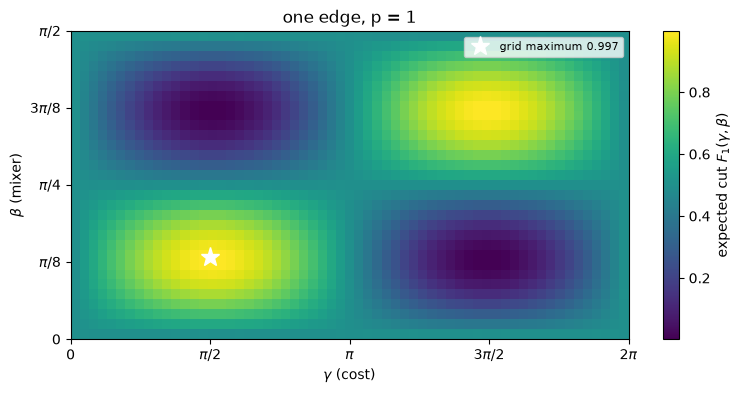

In [ ]:
gammas = np.linspace(0, 2 * np.pi, 61)
betas = np.linspace(0, np.pi / 2, 31)
F_edge = np.array([[expected_cut(qaoa(edge, 2, [g], [b]), edge) for g in gammas] for b in betas])
show_heatmap(gammas, betas, F_edge, title='one edge, p = 1')

**Your turn (textbook exercise 5).** From (9.53), find all $(\gamma, \beta) \in [0, 2\pi) \times [0, \pi/2)$ with $F_1 = 1$ and mark them:
`show_heatmap(gammas, betas, F_edge, marks=[(g1, b1), ...])`.

In [ ]:
# show_heatmap(gammas, betas, F_edge, marks=[(..., ...), (..., ...)])

<details>
<summary>Solution</summary>

```python
# sin(4 beta) sin(gamma) = 1: either both +1 or both -1
show_heatmap(gammas, betas, F_edge, marks=[(np.pi / 2, np.pi / 8), (3 * np.pi / 2, 3 * np.pi / 8)])
```

</details>

### 3.4 A triangle

Three vertices, three edges. An odd cycle cannot be cut completely: the best cut is 2. **Baseline first:** a random guess gives cut 2 for
6 of the 8 bit strings, so its mean is $1.5$ and $P(\text{optimum}) = 3/4$. QAOA has to beat that.

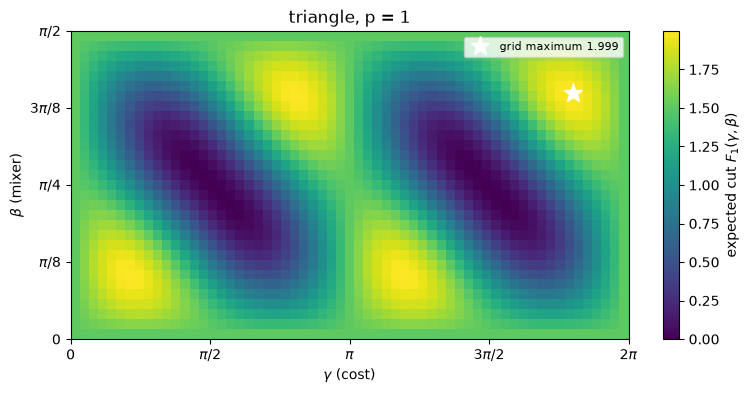

In [ ]:
triangle = [(0, 1), (1, 2), (0, 2)]
F_tri = np.array([[expected_cut(qaoa(triangle, 3, [g], [b]), triangle) for g in gammas] for b in betas])
show_heatmap(gammas, betas, F_tri, title='triangle, p = 1')

**Your turn (textbook exercise 6).**

1. Find the exact optimum by brute force: `cut_value` of all 8 bit strings `format(k, '03b')`.
2. Take the best grid point, `b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)`, build `qaoa(...)` with `gammas[g]`, `betas[b]`,
   add `measure_all()` and run it.
3. From the counts compute the mean cut, the best sampled cut and the fraction of optimal samples. Compare with the random guess.

In [ ]:
# for k in range(8):
#     bits = format(k, '03b')
#     print(bits, cut_value(bits, triangle))
# b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
# qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
# ...

<details>
<summary>Solution</summary>

```python
for k in range(8):
    bits = format(k, '03b')
    print(bits, cut_value(bits, triangle))         # 000 and 111 cut 0, all others cut 2

b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
qc.measure_all()
counts = run(qc)

mean = sum(n * cut_value(bits, triangle) for bits, n in counts.items()) / shots
best = max(cut_value(bits, triangle) for bits in counts)
p_opt = sum(n for bits, n in counts.items() if cut_value(bits, triangle) == 2) / shots
print(counts)
print(f'mean cut {mean:.3f} (random 1.5), best sample {best}, P(optimum) = {p_opt:.3f} (random 0.75)')
```

</details>

The same evaluation as a function, and a figure: the bit strings sorted by cut value, the dotted line is a random guess, and on the left the
best sampled cut (blue and orange are the two groups, red edges are cut).

C_max = 2:  mean cut 2.000 (ratio 1.000),  best sample 2,  P(optimum) = 1.000


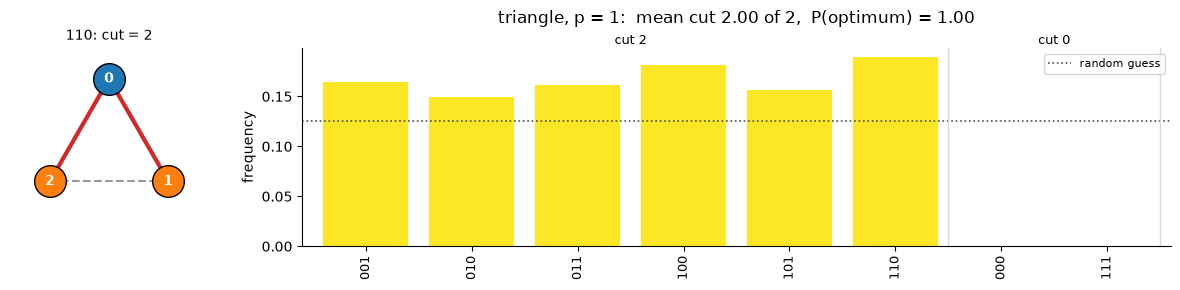

In [ ]:
def report(counts: dict, edges) -> None:
    n = len(next(iter(counts)))
    c_max = max(cut_value(format(k, f'0{n}b'), edges) for k in range(2**n))
    total = sum(counts.values())
    mean = sum(m * cut_value(bits, edges) for bits, m in counts.items()) / total
    best = max(cut_value(bits, edges) for bits in counts)
    p_opt = sum(m for bits, m in counts.items() if cut_value(bits, edges) == c_max) / total
    print(f'C_max = {c_max}:  mean cut {mean:.3f} (ratio {mean / c_max:.3f}),  best sample {best},  P(optimum) = {p_opt:.3f}')


b, g = np.unravel_index(F_tri.argmax(), F_tri.shape)
qc = qaoa(triangle, 3, [gammas[g]], [betas[b]])
qc.measure_all()
counts_tri = run(qc)
report(counts_tri, triangle)
show_samples(triangle, {'triangle, p = 1': counts_tri})

### 3.5 More layers: a ring of four

The square $0-1-2-3-0$ can be cut completely: $0101$ or $1010$, cut 4. With $p = 1$ the best QAOA gets is $F_1 = 3$; each edge "sees" only
its neighbours. With $p = 2$ we have four parameters, a grid is no longer practical, so we let COBYLA search from several random starting
points (*restarts*, textbook 9.7.3). The cost is again the exact $F_p$; on hardware it would be a sampled estimate.

p = 1: F_p = 3.000,  gammas = [2.356],  betas = [2.749]
C_max = 4:  mean cut 2.978 (ratio 0.745),  best sample 4,  P(optimum) = 0.515


p = 2: F_p = 4.000,  gammas = [ 2.237 -1.119],  betas = [1.011 1.119]
C_max = 4:  mean cut 4.000 (ratio 1.000),  best sample 4,  P(optimum) = 1.000


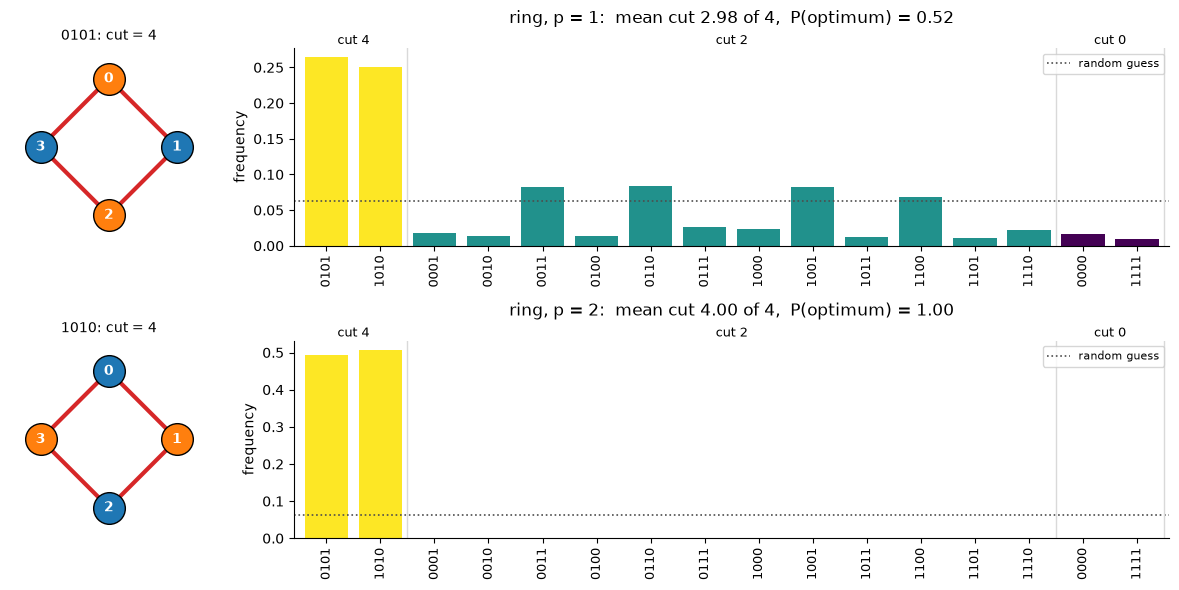

In [ ]:
ring = [(0, 1), (1, 2), (2, 3), (3, 0)]


def best_qaoa(edges, n: int, p: int, starts: int = 5, seed: int = 1):
    # Maximise F_p from several random starting points; returns (F_p, gammas, betas)
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(starts):
        x0 = rng.uniform(0, np.pi, 2 * p)
        res = minimize(lambda x: -expected_cut(qaoa(edges, n, x[:p], x[p:]), edges), x0, method='COBYLA')
        if best is None or res.fun < best.fun:
            best = res
    return -best.fun, best.x[:p], best.x[p:]


samples = {}
for p in [1, 2]:
    F, g, b = best_qaoa(ring, 4, p)
    print(f'p = {p}: F_p = {F:.3f},  gammas = {np.round(g, 3)},  betas = {np.round(b, 3)}')
    qc = qaoa(ring, 4, g, b)
    qc.measure_all()
    samples[f'ring, p = {p}'] = run(qc)
    report(samples[f'ring, p = {p}'], ring)

show_samples(ring, samples)

**Your turn.** A harder graph, the "house": a square $0-1-2-3$ with a roof vertex 4 on top of the edge $2-3$.

1. Run the same for `house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]` with $p = 1, 2, 3$ (takes a minute or two).
2. How do the mean cut and $P(\text{optimum})$ change with $p$? Look at `qaoa(house, 5, g, b).draw('mpl')` for $p = 3$: how many gates per layer?
3. In theory $F_{p+1} \ge F_p$, because an extra layer with $\gamma = \beta = 0$ does nothing. Why can the optimiser still return a worse
   result for larger $p$?

In [ ]:
house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]

# samples_house = {}
# for p in [1, 2, 3]:
#     F, g, b = best_qaoa(house, 5, p)
#     ...
# show_samples(house, samples_house)

<details>
<summary>Solution</summary>

```python
house = [(0, 1), (1, 2), (2, 3), (3, 0), (2, 4), (3, 4)]

samples_house = {}
for p in [1, 2, 3]:
    F, g, b = best_qaoa(house, 5, p, starts=10)
    print(f'p = {p}: F_p = {F:.3f}')
    qc = qaoa(house, 5, g, b)
    qc.measure_all()
    samples_house[f'house, p = {p}'] = run(qc)
    report(samples_house[f'house, p = {p}'], house)
show_samples(house, samples_house)

# 2. P(optimum) grows from about 0.4 (p = 1, 2) to about 0.8 (p = 3). Every layer has 6 RZZ (each 2 CNOTs) and 5 RX.
#    With the default starts=5, p = 1 gets stuck in a local optimum (F_1 = 3.5 instead of 4.1): restarts matter.
# 3. More parameters = a harder search: local optima, flat regions, more evaluations. On hardware also deeper circuits and more noise.
qaoa(house, 5, g, b).draw('mpl', fold=-1)
```

</details>

### 3.6 From the expectation value to a solution

QAOA's answer is **a bit string**, the best one among the final samples, not the mean $F_p$. The mean alone does not tell how often we hit
the optimum (textbook table 9.3):

| distribution | $P(C=0)$ | $P(C=1)$ | $P(C=2)$ | $E[C]$ | $P(\text{optimum})$ |
|---|:-:|:-:|:-:|:-:|:-:|
| A | 0 | 1 | 0 | 1 | 0 |
| B | 1/2 | 0 | 1/2 | 1 | 1/2 |

The ring with $p = 1$ above is a real example: mean cut 3 of 4, but it finds the optimum in only about half of the samples.

If a single sample is optimal with probability $q$, then $N$ independent samples contain at least one optimum with probability

$$1 - (1 - q)^N \ge 1 - \delta \quad\Longleftrightarrow\quad N \ge \frac{\ln\delta}{\ln(1 - q)} .$$

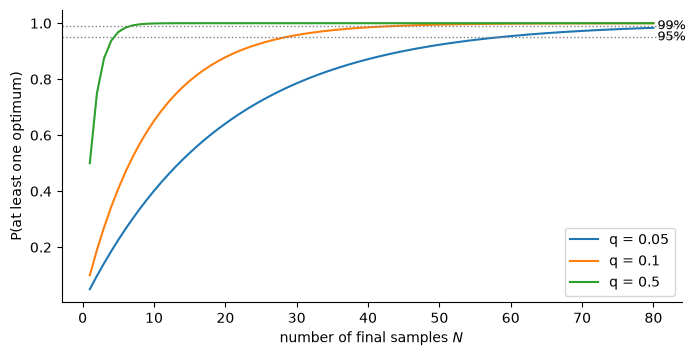

In [ ]:
show_success([0.05, 0.1, 0.5])

**Your turn (textbook exercise 8).**

1. For $q = 0.05$: how many final samples give success with probability at least 95 %?
2. The ring with $p = 1$ has $q \approx 0.5$. How many samples for 99 %?
3. Compare with the number of shots spent *during* the optimisation (1.5): which part of the budget dominates?

In [ ]:
# q, delta = 0.05, 0.05
# print(np.ceil(np.log(delta) / np.log(1 - q)))

<details>
<summary>Solution</summary>

```python
for q, delta in [(0.05, 0.05), (0.5, 0.01)]:
    print(f'q = {q}, success {1 - delta:.0%}: N >= {int(np.ceil(np.log(delta) / np.log(1 - q)))}')
# 59 and 7 samples. The optimisation itself used tens of thousands of shots (1.5): the final sampling is cheap,
# the hybrid loop is what costs. A fair comparison with classical methods has to count all of it.
```

</details>

## Summary

* A variational algorithm = a short parametrised circuit + measurements + a classical optimiser. The energy is estimated from many shots, one
  measurement setting for each group of commuting Pauli terms.
* Variational principle: $E_0 \le E_A \le E(\hat\theta)$. The ansatz must contain a good state (1.6), and the landscape must not be flat (1.8).
* Shot noise falls as $1/\sqrt N$: ten times more precision costs a hundred times more shots.
* QUBO $\to$ Ising via $x_i = (1 - z_i)/2$; constraints go in as penalties with a large enough $P$.
* QAOA: the cost layer writes the quality of each bit string into its phase, the mixer turns phases into probabilities. More layers $p$ can
  help, but cost parameters, depth and optimisation effort.
* The result of QAOA is a sampled bit string. Report the mean, the best sample and $P(\text{optimum})$, and compare with a random guess and a
  classical method.